<a href="https://colab.research.google.com/github/jenxhua/nvda_stock_analysis/blob/main/Project4_NVDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 4 - Data Visualizations
MGS 314 - Fall 2026

Name: Jennifer Chen

This project tracks NVDA stock from 2021 to 2025.

In [ ]:
# Import the packages
import datetime as dt              # for setting the start and end dates
import matplotlib.pyplot as plt    # for making charts
from matplotlib import style       # for picking a chart style
import pandas as pd                # for working with the data table
import yfinance as yf              # for downloading stock data from Yahoo Finance

In [ ]:
# Pick the stock ticker
ticker = 'NVDA'

In [ ]:
#Set a time frame.
startDate = dt.datetime(2021,1,1)
endDate = dt.datetime(2025,12,31)
#Pick a style:
style.use('ggplot')
#Get the data from Yahoo Finance:
df = yf.download(ticker, start=startDate, end=endDate,
                 auto_adjust=False, multi_level_index=False)
df.head()

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-01-04,13.05,13.11,13.65,12.96,13.10,560640000
2021-01-05,13.34,13.40,13.44,13.09,13.10,322760000
2021-01-06,12.55,12.61,13.24,12.59,13.22,580424000
2021-01-07,13.28,13.34,13.38,12.89,12.97,461480000
2021-01-08,13.21,13.28,13.42,13.04,13.36,292528000


In [ ]:
# Format the data
# Check the column types and look for missing values (Pandas Part 2, slide 9)
df.info()

# Remove any rows with missing values (slide 18)
df = df.dropna()

# Drop Adj Close since we only use Close in our charts (slide 7)
df = df.drop(['Adj Close'], axis=1)

# Add a 100 day moving average column (Week 13, slide 8)
df['100ma'] = df['Close'].rolling(window=100, min_periods=0).mean()

# Show 2 decimal places for easier viewing (Week 13, slide 5)
pd.set_option('display.precision', 2)

# Check that the values look reasonable (slide 23)
df.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1254 entries, 2021-01-04 to 2025-12-30
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1254 non-null   float64
 1   Close      1254 non-null   float64
 2   High       1254 non-null   float64
 3   Low        1254 non-null   float64
 4   Open       1254 non-null   float64
 5   Volume     1254 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 68.6 KB


,Close,High,Low,Open,Volume,100ma
count,1254.00,1254.00,1254.00,1254.00,1.25e+03,1254.00
mean,67.13,68.27,65.87,67.14,3.95e+08,60.39
std,57.40,58.25,56.47,57.46,1.83e+08,52.18
min,11.23,11.73,10.81,10.97,6.55e+07,13.04
25%,19.42,19.69,18.90,19.33,2.44e+08,18.28
50%,41.83,42.43,40.91,41.59,3.81e+08,29.80
75%,118.50,121.57,116.54,118.70,5.06e+08,115.96
max,207.04,212.19,205.56,208.08,1.54e+09,182.93


In [ ]:
#Export to a csv
df.to_csv('nvda.csv')
#Reduce decimal places for easier viewing
pd.set_option("display.precision", 2)
#Check the data
df = pd.read_csv('nvda.csv', parse_dates=True, index_col=0)
df

,Close,High,Low,Open,Volume,100ma
Date,,,,,,
2021-01-04,13.11,13.65,12.96,13.10,560640000,13.11
2021-01-05,13.40,13.44,13.09,13.10,322760000,13.26
2021-01-06,12.61,13.24,12.59,13.22,580424000,13.04
2021-01-07,13.34,13.38,12.89,12.97,461480000,13.12
2021-01-08,13.28,13.42,13.04,13.36,292528000,13.15
...,...,...,...,...,...,...
2025-12-23,189.21,189.33,182.90,182.97,174873600,182.56
2025-12-24,188.61,188.91,186.59,187.94,65528500,182.65
2025-12-26,190.53,192.69,188.00,189.92,139740300,182.77


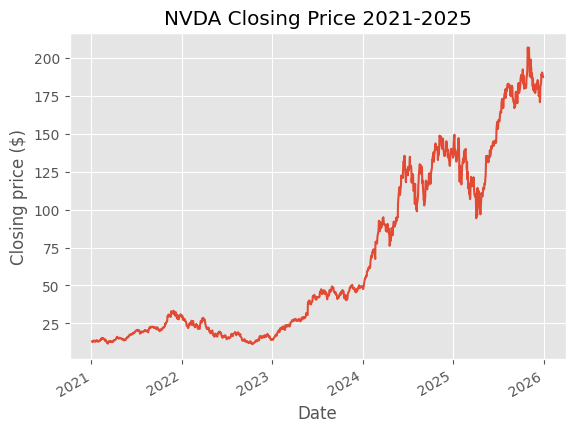

In [ ]:
# Check the plot
df['Close'].plot()
plt.title('NVDA Closing Price 2021-2025')
plt.ylabel('Closing price ($)')
plt.show()

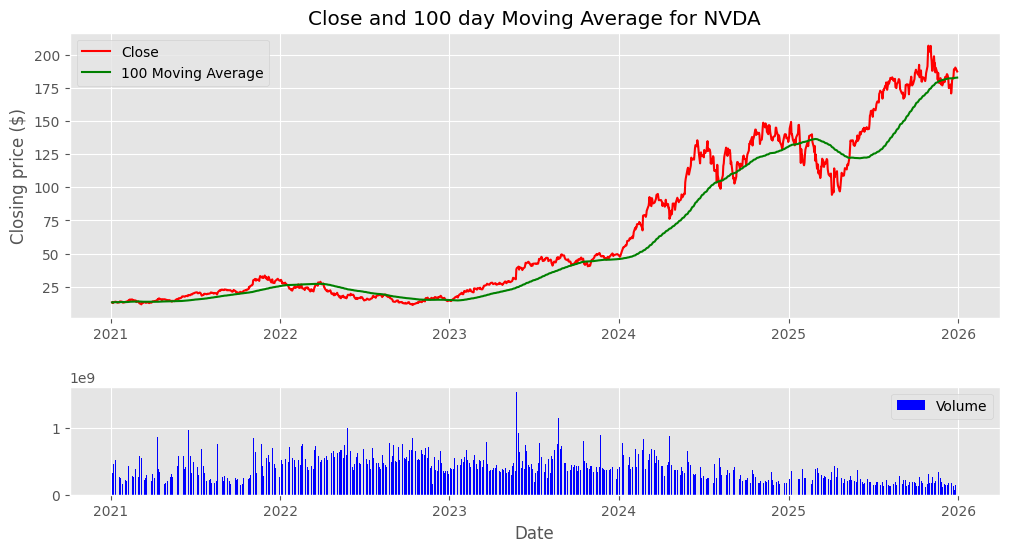

In [ ]:
#The size for our chart:
plt.figure(figsize = (12,6))
#Plotting Close and SMA lines:
ax1 = plt.subplot2grid((8,1),(0,0),rowspan=5,colspan=1)
ax2 = plt.subplot2grid((8,1),(6,0),rowspan=3,colspan=1, sharex=ax1)
ax1.plot(df.index,df['Close'], 'r',label='Close')
ax1.plot(df.index,df['100ma'], 'g', label= "100 Moving Average")
plt.xlabel('Date')
#ax1.set_xlabel('Date')
ax1.set_ylabel('Closing price ($)')
ax1.set_title('Close and 100 day Moving Average for NVDA')
ax1.legend()

ax2.bar(df.index,df['Volume'], label = "Volume", color='b')
ax2.legend()
plt.show()